# 03 · Маркет ВКонтакте vs Партнёр: где теряется покупатель

**Отвечает на вопрос кейса №4:** определить роль Маркета ВКонтакте на основе данных.
**Данные:** листы «итоги», «по дням», «источники», «категории», «Покупатели», «Покупатели по регионам».

«Партнёр 1» — условный внешний маркетплейс, чьи товары представлены во ВКонтакте.
Это **естественный бенчмарк внутри одной платформы**: тот же трафик ВКонтакте,
но другая модель сделки. Сравнение показывает, что дело не в пользователях, а в механике.

## План
1. Две воронки и **декомпозиция разрыва** по заказам (где именно теряется покупатель).
2. Источники трафика: интент vs браузинг.
3. Категории: ассортиментный разрыв и «мёртвый трафик».
4. Аудитория и география: кто покупает.
5. Динамика за месяц: куда движутся две модели.
6. Роль Маркета: три альтернативы и выбор на данных.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY, VK_DAU_2026Q3

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
%matplotlib inline

d = data.load_all()
t, day, src, cat, byr, reg = d["totals"], d["daily"], d["sources"], d["categories"], d["buyers"], d["regions"]
num = lambda m, c="Маркет Вконтакте": float(pd.to_numeric(pd.Series([t.loc[m, c]]), errors="coerce").iloc[0])

## 1. Две воронки: одинаковый трафик, разная судьба покупателя

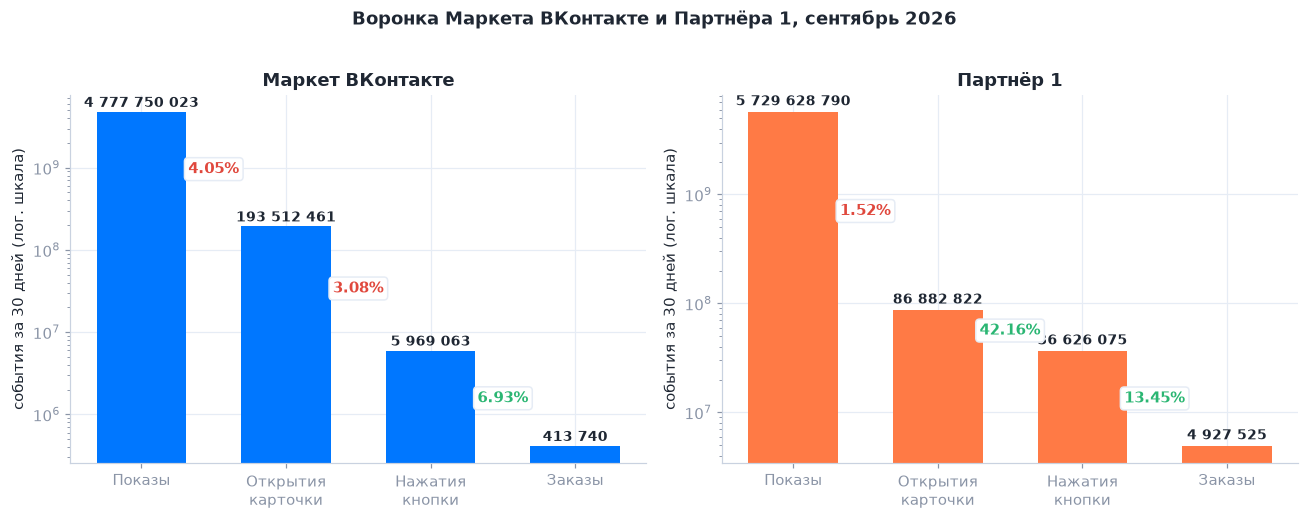

,Маркет ВКонтакте,Партнёр 1
segment,Маркет ВКонтакте,Партнёр 1
impressions,4777750023.0,5729628790.0
card_opens,193512461.0,86882822.0
button_clicks,5969063.0,36626075.0
orders,413740.0,4927525.0
gmv,1564546740.0,5119514685.0
buyers,296148.0,2901334.0
ctr_impression_to_open,0.040503,0.015164
click_rate_open_to_click,0.030846,0.421557
click_to_order,0.069314,0.134536


In [2]:
f = an.funnel_table(t)
data.save_table(f, "03_funnel")
viz.funnel_compare(f)
f.T.rename(columns={0: "Маркет ВКонтакте", 1: "Партнёр 1"}).round(4)

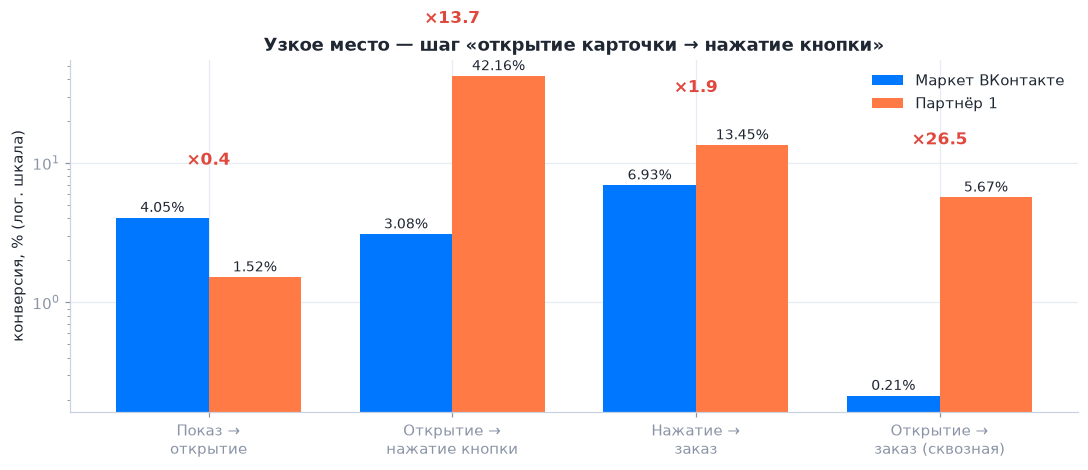

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/funnel_step_conversions.png')

In [3]:
viz.step_conversion_bars(f)

**Факты:**
* Маркет получает **в 2,2 раза больше открытий карточки** (193,5 млн против 86,9 млн) — интерес есть.
* Но заказов **в 11,9 раза меньше** (414 тыс. против 4,93 млн).
* Провал на шаге **«открытие карточки → нажатие кнопки»**: 3,08% против 42,16% — **разрыв ×13,7**.
* Средний чек Маркета **3 781 ₽** против **1 039 ₽** у Партнёра (×3,6) — другая корзина.

Пользователь ВКонтакте **хочет смотреть товары**, но в карточке Маркета **не видит действия, которое ведёт к покупке**.

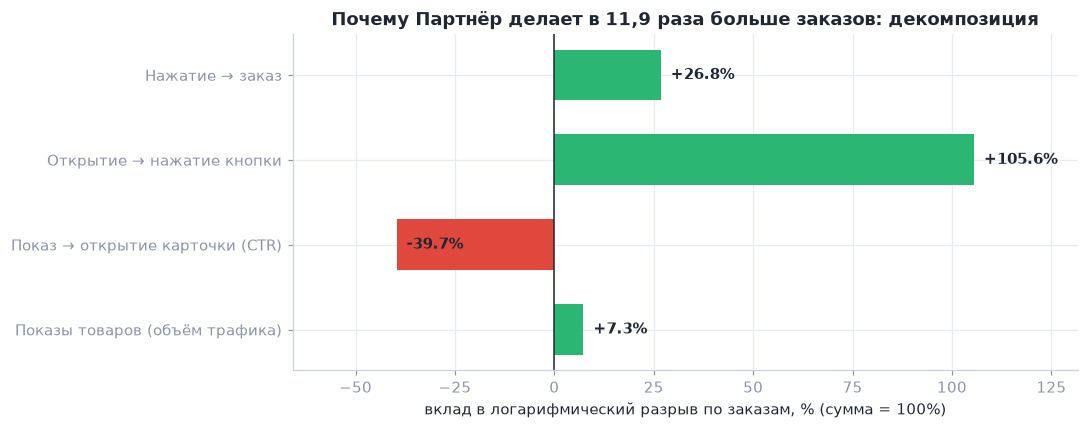

,step,ratio_pt_vs_vk,log_contribution
0,Показы товаров (объём трафика),1.199232,7.3
1,Показ → открытие карточки (CTR),0.374388,-39.7
2,Открытие → нажатие кнопки,13.666561,105.6
3,Нажатие → заказ,1.940962,26.8


In [4]:
gap = an.gap_decomposition(f)
data.save_table(gap, "03_gap_decomposition")
fig, ax = plt.subplots(figsize=(10, 4))
colors = [GOOD if v > 0 else BAD for v in gap.log_contribution]
ax.barh(gap.step, gap.log_contribution * 100, color=colors, height=0.6)
for i, v in enumerate(gap.log_contribution * 100):
    ax.text(v, i, f"  {v:+.1f}%", va="center", fontsize=10, fontweight="bold")
ax.axvline(0, color="#1F2733", lw=1)
ax.set_xlabel("вклад в логарифмический разрыв по заказам, % (сумма = 100%)")
ax.set_title("Почему Партнёр делает в 11,9 раза больше заказов: декомпозиция")
ax.margins(x=0.18)
fig.tight_layout(); viz.save(fig, "03_gap_decomposition")
gap.assign(log_contribution=lambda x: (x.log_contribution*100).round(1))

> **Это главный слайд проблематики.**
> **106% разрыва** по заказам объясняется одним шагом — «открытие карточки → нажатие кнопки».
> Более того, по CTR «показ → открытие» Маркет **лучше** Партнёра (4,05% против 1,52%, вклад −40%):
> трафик и интерес — не проблема. Проблема — **карточка не продаёт**.
>
> Что стоит за шагом «нажатие кнопки»: в Маркете кнопка чаще ведёт в переписку с продавцом
> или на внешний ресурс, у Партнёра — в корзину с оплатой и доставкой.
> Отсюда продуктовый приоритет №1: **сделать карточку товарной сделкой, а не объявлением**.

### 1.1. Что мы не видим: заказ, оплата и внешний сайт

In [5]:
obs = pd.DataFrame([
    ["Оформленные заказы Маркета", num("Оформленные заказы")],
    ["Оплаченные заказы Маркета", num("Оплаченные заказы")],
    ["Доля оплаченных", num("Оплаченные заказы") / num("Оформленные заказы")],
    ["Прямые переходы к Партнёру без открытия карточки", num("Прямые переходы к Партнёру 1 (без открытия карточки)", "Партнёр 1")],
    ["Заказы Партнёра / (нажатия + прямые переходы)",
     num("Оформленные заказы", "Партнёр 1") / (num("Нажатия на кнопку в карточке", "Партнёр 1") + num("Прямые переходы к Партнёру 1 (без открытия карточки)", "Партнёр 1"))],
], columns=["показатель", "значение"])
obs

,показатель,значение
0,Оформленные заказы Маркета,4.137400e+05
1,Оплаченные заказы Маркета,4.903000e+03
2,Доля оплаченных,1.185044e-02
3,Прямые переходы к Партнёру без открытия карточки,1.069147e+08
4,Заказы Партнёра / (нажатия + прямые переходы),3.432840e-02


У Партнёра **106,9 млн прямых переходов** на внешнюю площадку **без открытия карточки** —
то есть контент ведёт мимо витрины VK сразу в корзину маркетплейса.
ВКонтакте в этой схеме — **источник трафика**, а не место сделки.
Это и есть ответ на вопрос Киры из кейса: *«а если продажа заканчивается на внешнем сайте, мы её увидим?»* —
> увидим только как «оформленный заказ», без оплаты, возвратов и выкупа.

## 2. Источники трафика: интент против браузинга

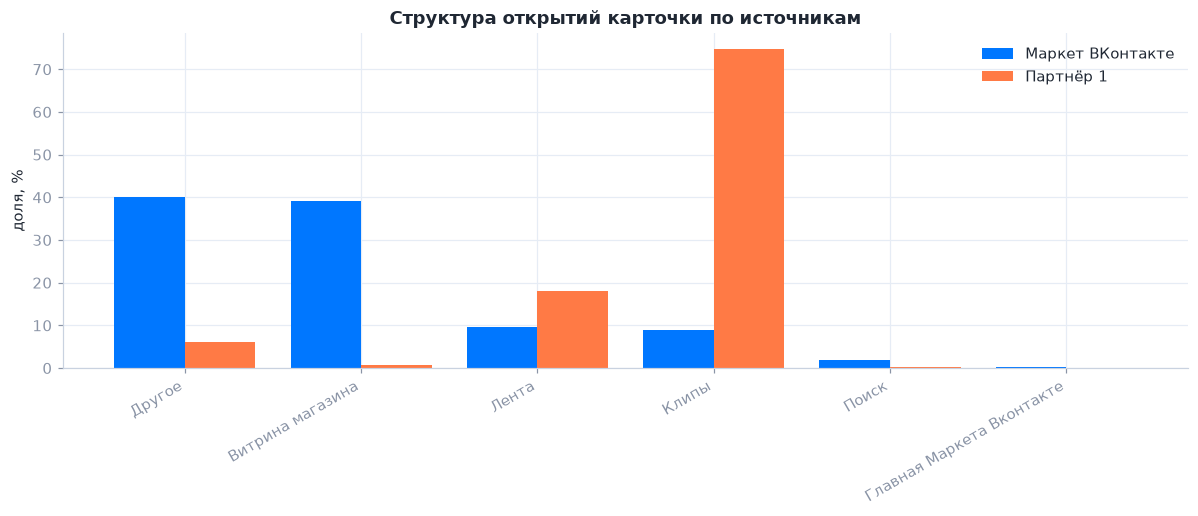

,Источник,Маркет Вконтакте,share_vk,Партнёр 1,share_pt,type
0,Другое,77753037.0,40.2,5380616,6.2,витрина/браузинг
1,Витрина магазина,75604323.0,39.1,714540,0.8,витрина/браузинг
2,Лента,18795696.0,9.7,15622386,18.0,контент (вдохновение)
3,Клипы,17239066.0,8.9,64917109,74.7,контент (вдохновение)
4,Поиск,3707521.0,1.9,159788,0.2,поиск (интент)
5,Главная Маркета Вконтакте,412818.0,0.2,88383,0.1,витрина/браузинг


In [6]:
s = src.copy()
s["type"] = np.where(s["Источник"].isin(["Лента", "Клипы"]), "контент (вдохновение)",
             np.where(s["Источник"] == "Поиск", "поиск (интент)", "витрина/браузинг"))
data.save_table(s, "03_sources")
viz.grouped_share(s.sort_values("share_vk", ascending=False), "Источник", "share_vk", "share_pt",
                  "Структура открытий карточки по источникам", "03_sources")
s[["Источник", "Маркет Вконтакте", "share_vk", "Партнёр 1", "share_pt", "type"]].assign(
    share_vk=lambda x: (x.share_vk*100).round(1), share_pt=lambda x: (x.share_pt*100).round(1))

In [7]:
mix = s.groupby("type")[["share_vk", "share_pt"]].sum()
print((mix * 100).round(1).to_string())
print(f"\nРеферальные открытия Партнёра: {src.attrs['referral_opens']:,.0f} "
      f"({src.attrs['referral_opens']/num('Открытия карточки товара','Партнёр 1'):.1%} его открытий)")
print(f"Реферальные от всех открытий (Маркет + Партнёр): "
      f"{src.attrs['referral_opens']/(num('Открытия карточки товара')+num('Открытия карточки товара','Партнёр 1')):.1%}")

                       share_vk  share_pt
type                                     
витрина/браузинг           79.5       7.1
контент (вдохновение)      18.6      92.7
поиск (интент)              1.9       0.2

Реферальные открытия Партнёра: 82,324,081 (94.8% его открытий)
Реферальные от всех открытий (Маркет + Партнёр): 29.4%


**Диагноз модели:**
* Маркет: **79,5%** открытий — витрина, «Другое» и главная, то есть **браузинг без намерения купить**;
  контент даёт лишь 18,6%, поиск — 1,9%.
* Партнёр: **92,7%** — контент (клипы 74,7% + лента 18%), причём **94,8% его открытий реферальные**.

Это две принципиально разные механики: **«полка в магазине»** против **«рекомендация автора»**.
Данные говорят, что вторая конвертирует в заказ в 27 раз лучше (5,67% против 0,21%).

## 3. Категории: где трафик есть, а продаж нет

Здесь важно помнить оговорку из ноутбука 00: суммы заказов по категориям расходятся с итогами
на 5–7%, поэтому смотрим **структуру**, а не абсолютные доли.

In [8]:
c = cat.sort_values("opens_vk", ascending=False).copy()
data.save_table(c, "03_categories")
c[["category", "opens_vk", "orders_vk", "conv_vk", "conv_pt", "conv_gap_x", "open_share_vk", "order_share_vk"]].assign(
    conv_vk=lambda x: (x.conv_vk*100).round(3), conv_pt=lambda x: (x.conv_pt*100).round(2),
    open_share_vk=lambda x: (x.open_share_vk*100).round(1),
    order_share_vk=lambda x: (x.order_share_vk*100).round(1)).round(2)

,category,opens_vk,orders_vk,conv_vk,conv_pt,conv_gap_x,open_share_vk,order_share_vk
0,Гардероб,33022954,29029,0.09,2.88,32.75,17.1,6.7
1,Хобби и развлечения,32048705,110703,0.34,4.73,13.69,16.6,25.4
2,Другое,29082926,41,0.00,0.00,0.00,15.0,0.0
3,Дом и дача,26162824,35976,0.14,5.76,41.92,13.5,8.3
4,Продукты питания,20393319,195355,0.96,6.85,7.15,10.5,44.9
5,Красота и здоровье,11345073,13022,0.12,8.79,76.57,5.9,3.0
6,Транспорт,8590002,8254,0.10,5.79,60.25,4.4,1.9
7,Электроника,5768728,4519,0.08,1.10,14.02,3.0,1.0
8,Спорт и отдых,5632947,7781,0.14,4.39,31.76,2.9,1.8
9,Детские товары,4859516,10546,0.22,4.15,19.11,2.5,2.4


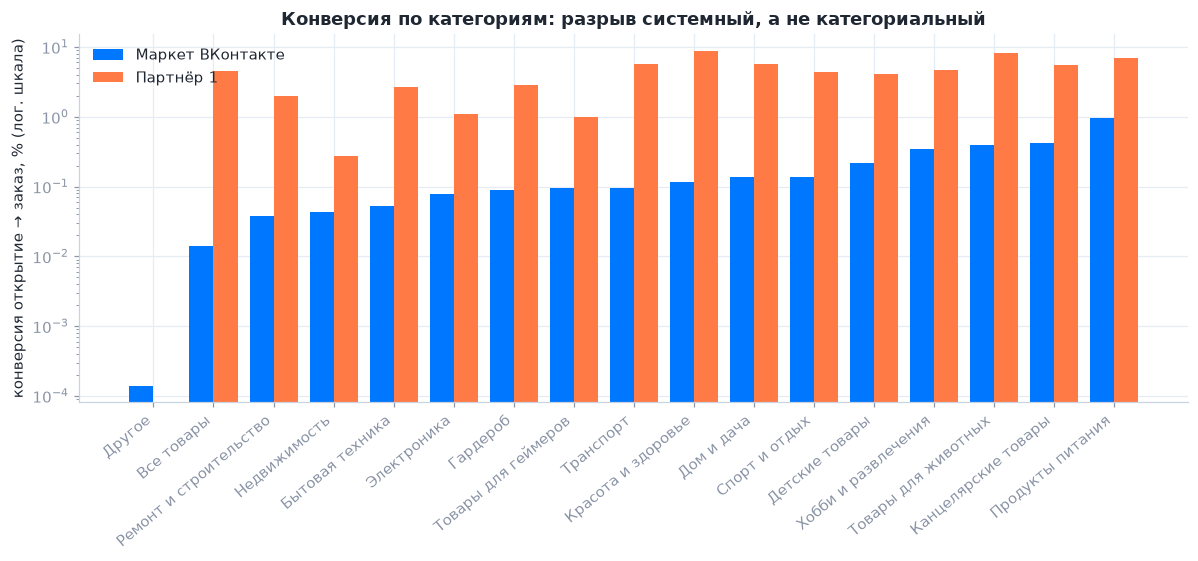

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/03_category_conversion.png')

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.2))
cc = c[c.opens_pt > 0].sort_values("conv_vk")
x = np.arange(len(cc)); w = 0.4
ax.bar(x - w/2, cc.conv_vk * 100, w, label="Маркет ВКонтакте", color=VK)
ax.bar(x + w/2, cc.conv_pt * 100, w, label="Партнёр 1", color=PARTNER)
ax.set_yscale("log"); ax.set_ylabel("конверсия открытие → заказ, % (лог. шкала)")
ax.set_xticks(x, cc.category, rotation=40, ha="right")
ax.set_title("Конверсия по категориям: разрыв системный, а не категориальный")
ax.legend()
fig.tight_layout(); viz.save(fig, "03_category_conversion")

In [10]:
dead = c[c.is_dead_traffic == 1]
dead_share_opens = dead.opens_vk.sum() / c.opens_vk.sum()
dead_share_orders = dead.orders_vk.sum() / c.orders_vk.sum()
print(f"Категории с конверсией <0,1%: {len(dead)} из {len(c)}")
print(f"Они забирают {dead_share_opens:.1%} открытий карточки Маркета и дают {dead_share_orders:.1%} заказов")
print("\nСписок:", ", ".join(dead.category))
print(f"\nКосинусная близость структуры: трафик Маркета vs заказы Маркета = {an.cosine(c.open_share_vk, c.order_share_vk):.3f}")
print(f"трафик Маркета vs заказы Партнёра = {an.cosine(c.open_share_vk, c.order_share_pt):.3f}")
print(f"заказы Маркета vs заказы Партнёра = {an.cosine(c.order_share_vk, c.order_share_pt):.3f}")

Категории с конверсией <0,1%: 10 из 18
Они забирают 46.3% открытий карточки Маркета и дают 11.0% заказов

Список: Гардероб, Другое, Транспорт, Электроника, Ремонт и строительство, Недвижимость, Бытовая техника, Все товары, Товары для геймеров, Не определена

Косинусная близость структуры: трафик Маркета vs заказы Маркета = 0.642
трафик Маркета vs заказы Партнёра = 0.557
заказы Маркета vs заказы Партнёра = 0.282


**Инсайт «мёртвый трафик».** Почти **половина открытий карточки Маркета (46%)** приходится на категории,
где конверсия ниже 0,1%: «Другое» (29 млн открытий → 41 заказ), «Гардероб», «Транспорт»,
«Недвижимость», «Бытовая техника», «Ремонт».

Это не «плохие продавцы» — это **несоответствие ассортимента и намерения**:
в Маркет заходят смотреть то, что покупают на классифайдах и маркетплейсах
(недвижимость, авто, техника), а внутри VK сделка по таким товарам не поддерживается.

При этом там, где товар «социальный» и импульсный, конверсия заметно выше:
продукты питания 0,96%, хобби 0,35%, товары для животных 0,40%, канцелярия 0,42%.

## 4. Кто покупает: аудитория и география

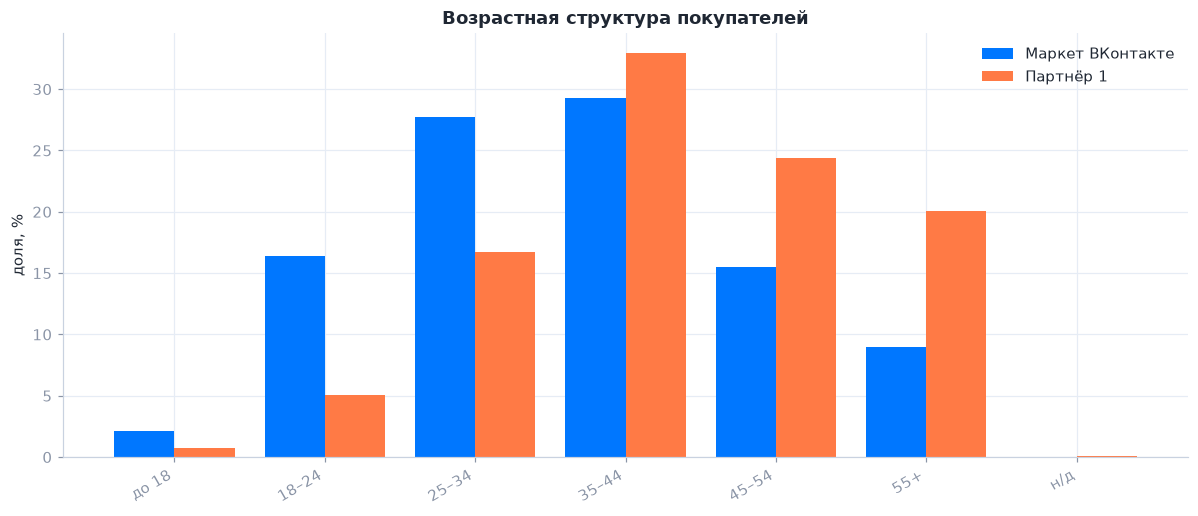

Пол (доли):
      buyers_vk  buyers_pt
sex                      
Ж        0.728      0.745
М        0.272      0.255
н/д      0.000      0.000

Возраст (доли):
        buyers_vk  buyers_pt
age                        
до 18      0.021      0.007
18–24      0.164      0.051
25–34      0.277      0.167
35–44      0.293      0.329
45–54      0.155      0.244
55+        0.090      0.201
н/д        0.000      0.001

Доля 35+: Маркет 53.8% | Партнёр 77.4%
Заказов на покупателя: Маркет 1.40 | Партнёр 1.70
Доля повторных покупателей: Маркет 19.0% | Партнёр 26.6%


In [11]:
age = byr.groupby("age")[["buyers_vk", "buyers_pt"]].sum()
age_share = age / age.sum()
order = ["до 18", "18–24", "25–34", "35–44", "45–54", "55+", "н/д"]
age_share = age_share.reindex([i for i in order if i in age_share.index])
data.save_table(age_share.reset_index(), "03_age_shares")
viz.grouped_share(age_share.reset_index(), "age", "buyers_vk", "buyers_pt",
                  "Возрастная структура покупателей", "03_age")
sex = byr.groupby("sex")[["buyers_vk", "buyers_pt"]].sum()
print("Пол (доли):\n", (sex / sex.sum()).round(3).to_string())
print("\nВозраст (доли):\n", age_share.round(3).to_string())
print(f"\nДоля 35+: Маркет {(age_share.loc[['35–44','45–54','55+'],'buyers_vk'].sum()):.1%} | "
      f"Партнёр {(age_share.loc[['35–44','45–54','55+'],'buyers_pt'].sum()):.1%}")
print(f"Заказов на покупателя: Маркет {num('Оформленные заказы')/num('Уникальные покупатели за 30 дней'):.2f} | "
      f"Партнёр {num('Оформленные заказы','Партнёр 1')/num('Уникальные покупатели за 30 дней','Партнёр 1'):.2f}")
print(f"Доля повторных покупателей: Маркет {num('Доля повторных покупателей (2+ заказа), %')}% | "
      f"Партнёр {num('Доля повторных покупателей (2+ заказа), %','Партнёр 1')}%")

* Обе модели — **женские** (73–75%), ядро 35–44.
* Маркет **моложе**: 18–34 дают 44% покупателей против 22% у Партнёра; у Партнёра 55+ — 20% против 9%.
* Партнёр **удерживает лучше**: 1,7 заказа на покупателя и 26,6% повторных против 1,4 и 19%.

Вывод: у Маркета есть аудитория молодых покупателей с более высоким чеком — это **не «мусорный» трафик**,
а недоиспользованный актив. Но частота покупок ниже → нет привычки покупать внутри VK.

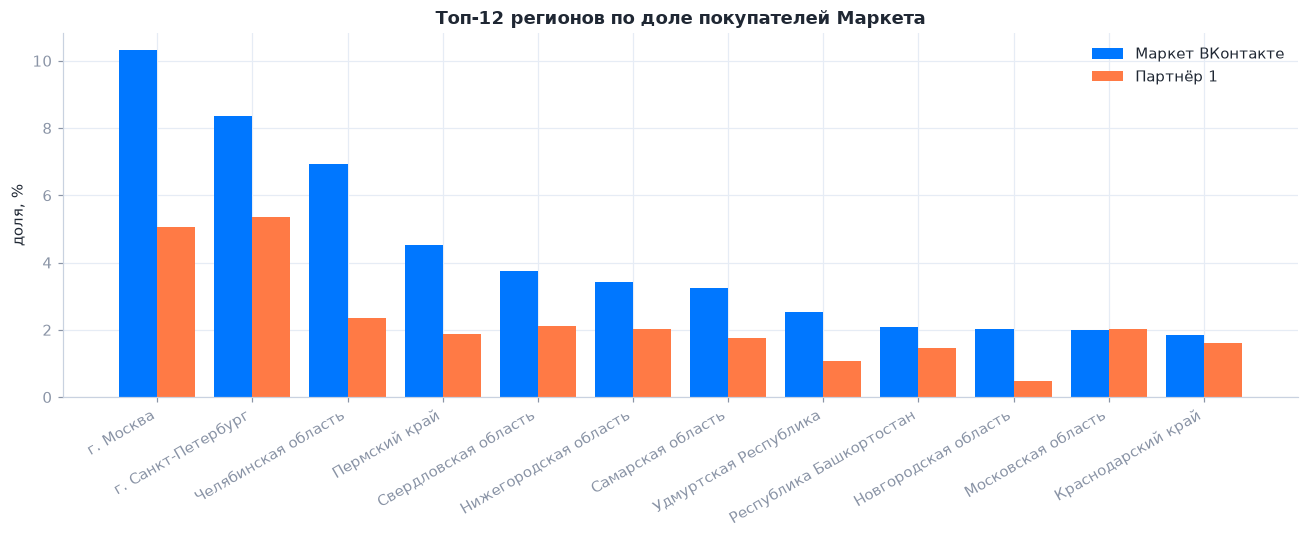

Москва + СПб: Маркет 18.6% | Партнёр 10.4%
HHI гео-концентрации: Маркет 0.0356 | Партнёр 0.1460

Регионы, где Маркет переиндексирован относительно Партнёра (доля VK / доля Партнёра):
                    region  share_vk  share_pt  index_vk_vs_pt
      Чеченская Республика    0.0006    0.0001          5.4145
      Новгородская область    0.0204    0.0048          4.2065
       Запорожская область    0.0004    0.0001          3.3228
       Челябинская область    0.0692    0.0234          2.9565
       Республика Дагестан    0.0012    0.0004          2.7382
           Курская область    0.0161    0.0059          2.7275
Республика Адыгея (Адыгея)    0.0014    0.0005          2.7042
       Сахалинская область    0.0012    0.0005          2.5442


In [12]:
r = reg.dropna(subset=["buyers_vk"]).copy()
top = r.nlargest(12, "share_vk")
data.save_table(r, "03_regions")
viz.grouped_share(top, "region", "share_vk", "share_pt", "Топ-12 регионов по доле покупателей Маркета",
                  "03_regions", figsize=(12, 5))
msk_spb = ["г. Москва", "г. Санкт-Петербург"]
print(f"Москва + СПб: Маркет {r[r.region.isin(msk_spb)].share_vk.sum():.1%} | "
      f"Партнёр {reg[reg.region.isin(msk_spb)].share_pt.sum():.1%}")
print(f"HHI гео-концентрации: Маркет {an.hhi(r.share_vk):.4f} | Партнёр {an.hhi(r.share_pt):.4f}")
print("\nРегионы, где Маркет переиндексирован относительно Партнёра (доля VK / доля Партнёра):")
print(r.nlargest(8, "index_vk_vs_pt")[["region", "share_vk", "share_pt", "index_vk_vs_pt"]].round(4).to_string(index=False))

Маркет **более столичный** (18,6% против 10,4% в Москве и СПб) и в целом менее концентрирован
по стране (HHI 0,036 против 0,146 — у Партнёра база шире по объёму, но сильнее смещена в топ-регионы).
Переиндексированы industrial-регионы: Челябинская (×3,0), Пермский край (×2,4),
Новгородская (×4,2), Свердловская (×1,8) — доля покупателей Маркета выше, чем у Партнёра.

Практический смысл: **Маркет — канал регионального СМБ**, где у локального продавца
нет альтернативы в виде федерального маркетплейса. Это аргумент за роль «витрина локального бизнеса».

## 5. Динамика за месяц: модели движутся в разные стороны

In [13]:
metrics = ["Показы товаров: Маркет Вконтакте", "Открытия карточки: Маркет Вконтакте",
           "Заказы: Маркет Вконтакте", "GMV, ₽: Маркет Вконтакте",
           "Показы товаров: Партнёр 1", "Открытия карточки: Партнёр 1",
           "Заказы: Партнёр 1", "GMV, ₽: Партнёр 1", "DAU Маркета Вконтакте", "Поисковые запросы"]
trends = pd.DataFrame([an.trend(day, m) for m in metrics])
data.save_table(trends, "03_trends")
trends.assign(change_pct=lambda x: (x.change_pct*100).round(1)).round(4)

,metric,first7_avg,last7_avg,change_pct,slope_per_day,r2,p_value
0,Показы товаров: Маркет Вконтакте,1.619171e+08,1.558448e+08,-3.8,-3.941311e+05,0.3347,0.0008
1,Открытия карточки: Маркет Вконтакте,6.300750e+06,6.605006e+06,4.8,1.481101e+04,0.4906,0.0000
2,Заказы: Маркет Вконтакте,1.477357e+04,1.319900e+04,-10.7,-7.870570e+01,0.1433,0.0391
3,"GMV, ₽: Маркет Вконтакте",5.444700e+07,5.057296e+07,-7.1,-2.070909e+05,0.1496,0.0347
4,Показы товаров: Партнёр 1,1.842065e+08,1.953166e+08,6.0,7.206040e+05,0.2111,0.0106
5,Открытия карточки: Партнёр 1,2.842935e+06,3.111396e+06,9.4,1.512457e+04,0.2254,0.0080
6,Заказы: Партнёр 1,1.599707e+05,1.887313e+05,18.0,1.172292e+03,0.3421,0.0007
7,"GMV, ₽: Партнёр 1",1.407643e+08,2.134209e+08,51.6,2.932052e+06,0.7676,0.0000
8,DAU Маркета Вконтакте,1.256977e+05,1.282200e+05,2.0,1.104107e+02,0.0604,0.1907
9,Поисковые запросы,9.679893e+05,9.306101e+05,-3.9,-1.622005e+03,0.2343,0.0067


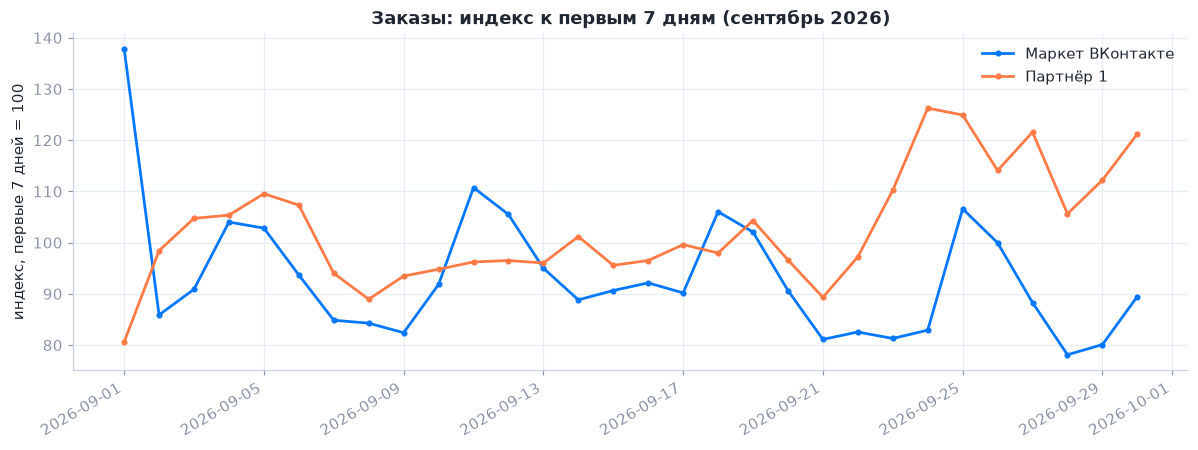

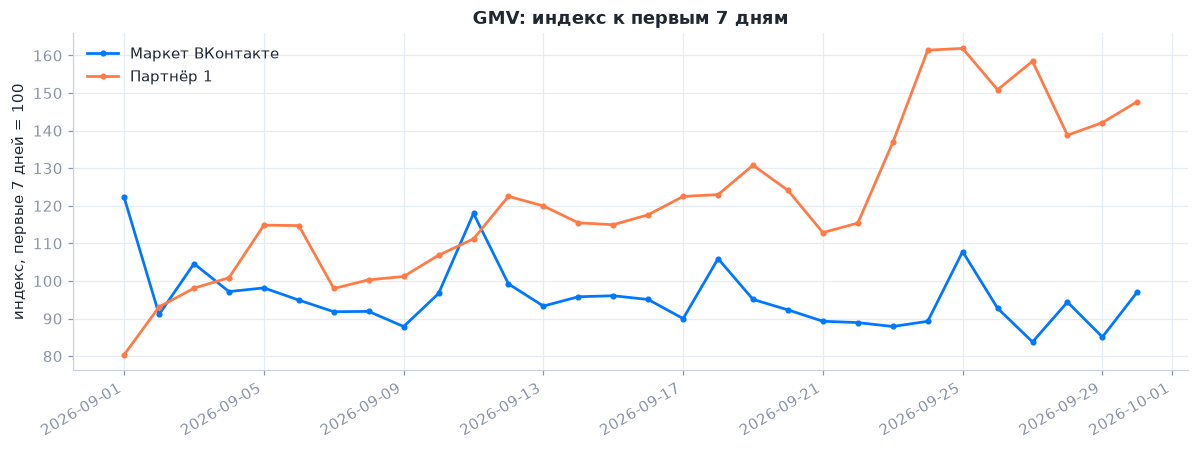

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/03_gmv_index.png')

In [14]:
viz.time_series(day, ["Заказы: Маркет Вконтакте", "Заказы: Партнёр 1"],
                ["Маркет ВКонтакте", "Партнёр 1"],
                "Заказы: индекс к первым 7 дням (сентябрь 2026)", "03_orders_index", normalize=True)
viz.time_series(day, ["GMV, ₽: Маркет Вконтакте", "GMV, ₽: Партнёр 1"],
                ["Маркет ВКонтакте", "Партнёр 1"],
                "GMV: индекс к первым 7 дням", "03_gmv_index", normalize=True)

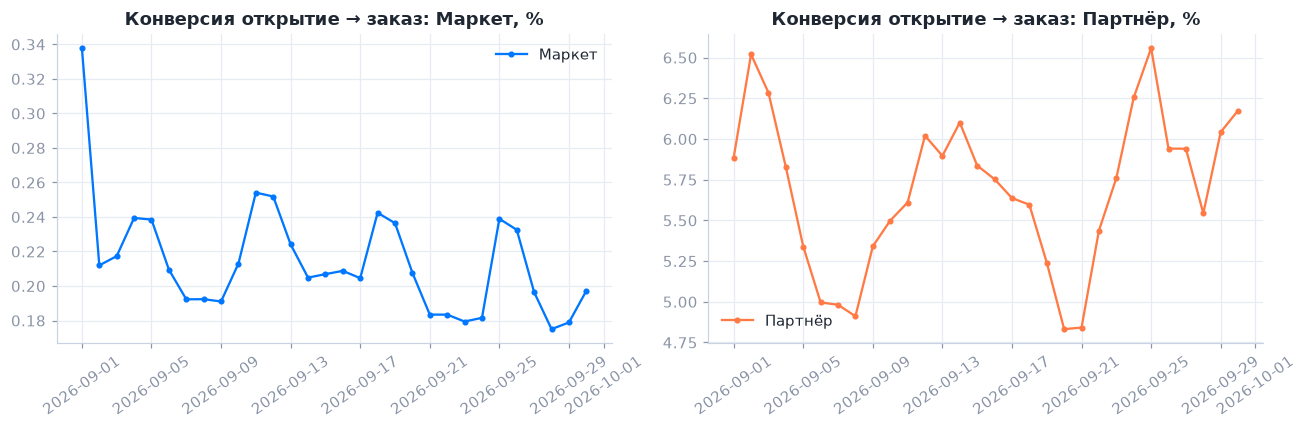

Конверсия Маркета: первые 7 дней 0.235% → последние 7 дней 0.200%
Конверсия Партнёра: 5.691% → 6.065%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(day.date, day.conv_vk * 100, color=VK, marker="o", ms=3, label="Маркет")
axes[0].set_title("Конверсия открытие → заказ: Маркет, %"); axes[0].legend()
axes[1].plot(day.date, day.conv_pt * 100, color=PARTNER, marker="o", ms=3, label="Партнёр")
axes[1].set_title("Конверсия открытие → заказ: Партнёр, %"); axes[1].legend()
for ax in axes: ax.tick_params(axis="x", rotation=35)
fig.tight_layout(); viz.save(fig, "03_conversion_dynamics")
print(f"Конверсия Маркета: первые 7 дней {day.conv_vk[:7].mean():.3%} → последние 7 дней {day.conv_vk[-7:].mean():.3%}")
print(f"Конверсия Партнёра: {day.conv_pt[:7].mean():.3%} → {day.conv_pt[-7:].mean():.3%}")

In [16]:
dow = day.groupby("dow")[["Заказы: Маркет Вконтакте", "Заказы: Партнёр 1"]].mean()
dow.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
print("Средние заказы по дням недели:\n", dow.round(0).to_string())
print(f"\nВыходные vs будни: Маркет {day[day.is_weekend==1]['Заказы: Маркет Вконтакте'].mean()/day[day.is_weekend==0]['Заказы: Маркет Вконтакте'].mean()-1:+.1%}, "
      f"Партнёр {day[day.is_weekend==1]['Заказы: Партнёр 1'].mean()/day[day.is_weekend==0]['Заказы: Партнёр 1'].mean()-1:+.1%}")

Средние заказы по дням недели:
     Заказы: Маркет Вконтакте  Заказы: Партнёр 1
Пн                   12294.0           156016.0
Вт                   14047.0           151823.0
Ср                   12740.0           166314.0
Чт                   13141.0           170118.0
Пт                   15784.0           169757.0
Сб                   15155.0           169745.0
Вс                   13577.0           168575.0

Выходные vs будни: Маркет +5.8%, Партнёр +4.1%


**Тренды за 30 дней (последние 7 дней к первым 7):**
* Маркет: показы −3,8%, заказы **−10,7%**, GMV −7,1%, конверсия падает с 0,235% до 0,200%.
* Партнёр: показы +6,0%, заказы **+18,0%**, GMV **+51,6%**, конверсия растёт с 5,69% до 6,07%.

Одна и та же аудитория ВКонтакте, один месяц — **две противоположные траектории**.
Контентно-реферальная модель растёт, витринная деградирует.
Это сильнейший аргумент в вопросе о роли Маркета: **проблема не в рынке, а в модели**.

Оговорка: один месяц не даёт сезонности; тренд нужно подтвердить на 3–6 месяцах.

### 5.1. Насколько Маркет вообще велик как «место»

In [17]:
dau = day["DAU Маркета Вконтакте"].mean()
mau = num("MAU Маркета Вконтакте (уникальные за 30 дней)", "Всего")
saw = num("Пользователи, видевшие товары за 30 дней", "Всего")
opened = num("Пользователи, открывавшие карточку товара за 30 дней", "Всего")
scale = pd.DataFrame([
    ["DAU Маркета (среднее за день)", dau],
    ["MAU Маркета", mau],
    ["DAU/MAU Маркета", dau / mau],
    ["DAU Маркета / DAU VK (90,8 млн)", dau / VK_DAU_2026Q3],
    ["Видели товары за 30 дней (вся платформа)", saw],
    ["Открывали карточку за 30 дней (вся платформа)", opened],
    ["Открывали / видели", opened / saw],
    ["Запросов в товарном поиске за день", day["Поисковые запросы"].mean()],
    ["Доля запросов с открытием карточки", day["Поисковые запросы с открытием карточки"].sum() / day["Поисковые запросы"].sum()],
], columns=["показатель", "значение"])
data.save_table(scale, "03_scale")
scale.round(4)

,показатель,значение
0,DAU Маркета (среднее за день),1.274063e+05
1,MAU Маркета,2.997341e+06
2,DAU/MAU Маркета,4.250000e-02
3,"DAU Маркета / DAU VK (90,8 млн)",1.400000e-03
4,Видели товары за 30 дней (вся платформа),6.661797e+07
5,Открывали карточку за 30 дней (вся платформа),2.733396e+07
6,Открывали / видели,4.103000e-01
7,Запросов в товарном поиске за день,9.528414e+05
8,Доля запросов с открытием карточки,1.839000e-01


> **Ключевой масштабный факт.**
> Маркет как отдельный экран — **127 тыс. DAU, это 0,14% дневной аудитории ВКонтакте**,
> а DAU/MAU = 4,3% (человек заходит раз в 3 недели).
> При этом **66,6 млн пользователей за месяц видят товары** и **27,3 млн открывают карточки** —
> то есть товарный опыт живёт **в ленте, клипах и поиске, а не в Маркете**.
>
> Отдельно: **28,6 млн товарных поисковых запросов в месяц** (953 тыс./день) с открытием карточки
> в 18,4% случаев — это единственный **интентный** вход, и он в 20 раз больше DAU Маркета.

## 6. Роль Маркета ВКонтакте: три альтернативы на данных

Кейс разрешает любой ответ, включая «отдельная витрина не нужна», если он обоснован.
Сравниваем альтернативы по единым критериям.

In [18]:
alt = pd.DataFrame([
    {"альтернатива": "A. Развивать как самостоятельный маркетплейс (destination)",
     "что говорят данные": "DAU 0,14% от VK; DAU/MAU 4,3%; конверсия открытие→заказ 0,21% и падает; 46% трафика — категории с конверсией <0,1%; заказы −10,7% за месяц",
     "плюсы": "высокий средний чек 3 781 ₽; узнаваемость бренда «Маркет»",
     "минусы": "нужны логистика, платежи, возвраты, ассортимент и цена как у WB/Ozon; конкуренция с 81% рынка заказов у маркетплейсов",
     "вердикт": "НЕ рекомендуется: нет ни аудитории, ни экономики для лобовой конкуренции"},
    {"альтернатива": "B. Маркет = товарная инфраструктура + поиск + витрина внутри сообщества",
     "что говорят данные": "27,3 млн открывают карточки вне Маркета; 28,6 млн поисковых запросов; 92,7% успешных открытий Партнёра — из контента; узкое место — шаг «карточка→кнопка» (×13,7)",
     "плюсы": "работает на существующем трафике; не требует своей логистики; монетизация через сделку и рекламу; усиливает сообщество как «магазин бренда»",
     "минусы": "нужна унификация карточки, чекаута и атрибуции; сложнее объяснить бизнесу «куда исчезла витрина»",
     "вердикт": "РЕКОМЕНДУЕТСЯ: превращает Маркет из места в слой (catalog + checkout + trust + search)"},
    {"альтернатива": "C. Полностью закрыть отдельную витрину",
     "что говорят данные": "79,5% открытий Маркета — витрина/браузинг; «Главная Маркета» даёт лишь 0,2% открытий; но поиск даёт 1,9% открытий и 28,6 млн запросов",
     "плюсы": "экономия ресурсов, фокус на контентной коммерции",
     "минусы": "теряем интентный поиск и точку возврата покупателя (история заказов, повторные покупки); 296 тыс. покупателей остаются без «дома»",
     "вердикт": "Частично: закрывать «Главную как destination», но сохранять поиск, заказы и профиль покупателя"},
])
data.save_table(alt, "03_market_role_alternatives")
alt

,альтернатива,что говорят данные,плюсы,минусы,вердикт
0,A. Развивать как самостоятельный маркетплейс (...,"DAU 0,14% от VK; DAU/MAU 4,3%; конверсия откры...",высокий средний чек 3 781 ₽; узнаваемость брен...,"нужны логистика, платежи, возвраты, ассортимен...","НЕ рекомендуется: нет ни аудитории, ни экономи..."
1,B. Маркет = товарная инфраструктура + поиск + ...,"27,3 млн открывают карточки вне Маркета; 28,6 ...",работает на существующем трафике; не требует с...,"нужна унификация карточки, чекаута и атрибуции...",РЕКОМЕНДУЕТСЯ: превращает Маркет из места в сл...
2,C. Полностью закрыть отдельную витрину,"79,5% открытий Маркета — витрина/браузинг; «Гл...","экономия ресурсов, фокус на контентной коммерции",теряем интентный поиск и точку возврата покупа...,"Частично: закрывать «Главную как destination»,..."


In [19]:
role = pd.DataFrame([
    ["Каталог и карточка (единый товарный слой)", "карточка = сделка: цена, наличие, доставка, оплата, кнопка «купить»",
     "рост шага открытие→нажатие (сейчас 3,08%)", "каждый +1 п.п. = +134 тыс. заказов/мес"],
    ["Товарный поиск и рекомендации", "интентный вход: 28,6 млн запросов/мес, 18,4% с открытием",
     "доля запросов с открытием и с заказом", "поиск — единственный канал с готовым намерением"],
    ["Витрина внутри сообщества", "магазин бренда/локального продавца, а не общая полка",
     "заказы на сообщество, доля продающих", "работает на региональный СМБ (переиндексация 2–4×)"],
    ["Профиль покупателя и повторные покупки", "история заказов, избранное, снижение цены, повторный заказ",
     "заказов на покупателя 1,4 → цель 1,7 (уровень Партнёра)", "+21% заказов без нового трафика"],
    ["Слой доверия и исполнения", "доставка, оплата, возвраты, статусы, рейтинг продавца",
     "доля оплаченных заказов (сейчас 1,2%)", "без этого невозможна монетизация комиссией"],
], columns=["функция Маркета в целевой модели", "что делаем", "метрика", "почему это важно"])
data.save_table(role, "03_market_target_role")
role

,функция Маркета в целевой модели,что делаем,метрика,почему это важно
0,Каталог и карточка (единый товарный слой),"карточка = сделка: цена, наличие, доставка, оп...","рост шага открытие→нажатие (сейчас 3,08%)",каждый +1 п.п. = +134 тыс. заказов/мес
1,Товарный поиск и рекомендации,"интентный вход: 28,6 млн запросов/мес, 18,4% с...",доля запросов с открытием и с заказом,поиск — единственный канал с готовым намерением
2,Витрина внутри сообщества,"магазин бренда/локального продавца, а не общая...","заказы на сообщество, доля продающих",работает на региональный СМБ (переиндексация 2...
3,Профиль покупателя и повторные покупки,"история заказов, избранное, снижение цены, пов...","заказов на покупателя 1,4 → цель 1,7 (уровень ...",+21% заказов без нового трафика
4,Слой доверия и исполнения,"доставка, оплата, возвраты, статусы, рейтинг п...","доля оплаченных заказов (сейчас 1,2%)",без этого невозможна монетизация комиссией


In [20]:
orders_per_pp = num("Оформленные заказы") / (f.loc[0, "click_rate_open_to_click"] * 100)
gmv_per_pp = num("GMV, ₽") / (f.loc[0, "click_rate_open_to_click"] * 100)
print(f"Чувствительность: +1 п.п. конверсии «открытие→нажатие» = +{orders_per_pp:,.0f} заказов/мес и +{gmv_per_pp:,.0f} ₽ GMV/мес")
print(f"Повторные покупки на уровне Партнёра (1,7 vs 1,4 заказа/покупателя): +{(1.7/1.4-1)*num('Оформленные заказы'):,.0f} заказов/мес")

Чувствительность: +1 п.п. конверсии «открытие→нажатие» = +134,131 заказов/мес и +507,214,097 ₽ GMV/мес
Повторные покупки на уровне Партнёра (1,7 vs 1,4 заказа/покупателя): +88,659 заказов/мес


In [21]:
data.save_key_numbers({
    "vk_orders": num("Оформленные заказы"), "pt_orders": num("Оформленные заказы", "Партнёр 1"),
    "vk_gmv": num("GMV, ₽"), "pt_gmv": num("GMV, ₽", "Партнёр 1"),
    "vk_aov": num("GMV, ₽") / num("Оформленные заказы"),
    "pt_aov": num("GMV, ₽", "Партнёр 1") / num("Оформленные заказы", "Партнёр 1"),
    "vk_ctr": float(f.loc[0, "ctr_impression_to_open"]),
    "vk_click_rate": float(f.loc[0, "click_rate_open_to_click"]),
    "pt_click_rate": float(f.loc[1, "click_rate_open_to_click"]),
    "vk_conv_open_to_order": float(f.loc[0, "conv_open_to_order"]),
    "pt_conv_open_to_order": float(f.loc[1, "conv_open_to_order"]),
    "orders_gap_x": float(f.loc[1, "orders"] / f.loc[0, "orders"]),
    "gap_contribution_button_step": float(gap.loc[2, "log_contribution"]),
    "vk_browse_share": float(mix.loc["витрина/браузинг", "share_vk"]),
    "pt_content_share": float(mix.loc["контент (вдохновение)", "share_pt"]),
    "dead_traffic_open_share": float(dead_share_opens),
    "dead_traffic_order_share": float(dead_share_orders),
    "market_dau": float(dau), "market_mau": float(mau),
    "market_dau_share_of_vk": float(dau / VK_DAU_2026Q3),
    "market_dau_mau": float(dau / mau),
    "search_queries_month": float(day["Поисковые запросы"].sum()),
    "search_open_rate": float(day["Поисковые запросы с открытием карточки"].sum() / day["Поисковые запросы"].sum()),
    "vk_orders_trend_pct": float(trends.loc[trends.metric == "Заказы: Маркет Вконтакте", "change_pct"].iloc[0] * 100),
    "pt_orders_trend_pct": float(trends.loc[trends.metric == "Заказы: Партнёр 1", "change_pct"].iloc[0] * 100),
    "pt_gmv_trend_pct": float(trends.loc[trends.metric == "GMV, ₽: Партнёр 1", "change_pct"].iloc[0] * 100),
    "orders_per_pp_click_rate": float(orders_per_pp),
    "gmv_per_pp_click_rate": float(gmv_per_pp),
}, "03_market")
print("Сохранено: outputs/tables/03_*.csv")

Сохранено: outputs/tables/03_*.csv


## Итоги ноутбука 03

1. **Разрыв ×11,9 по заказам на 106% объясняется шагом «карточка → нажатие кнопки»** (3,08% vs 42,16%).
   По CTR «показ → открытие» Маркет даже лучше — трафик не проблема.
2. **79,5% трафика Маркета — браузинг**, у Партнёра **92,7% — контент**, 94,8% его открытий реферальные.
3. **46% открытий Маркета — «мёртвый трафик»** (категории с конверсией <0,1%): ассортимент не соответствует намерению.
4. Маркет — **0,14% DAU ВКонтакте**, DAU/MAU 4,3%. Товарный опыт живёт в ленте, клипах и поиске.
5. За месяц **заказы Маркета −10,7%, Партнёра +18,0%, GMV Партнёра +51,6%**.
6. **Роль Маркета — не destination-маркетплейс, а товарная инфраструктура** (каталог+карточка+чекаут+доверие)
   плюс поиск и витрина внутри сообщества. Отдельную «главную как место» развивать нецелесообразно.
7. Два «бесплатных» рычага: **+1 п.п. конверсии кнопки = +134 тыс. заказов/мес**;
   повторность на уровне Партнёра = **+21% заказов** без нового трафика.

**Дальше:** ноутбук 04 — сценарная модель, монетизация и целевой путь бизнеса.